# Cloud vs Clear Sky Classification

This notebook implements **interpretable classifiers** for distinguishing *cloudy* and *clear* sky images, using simple image features (blueness, brightness, edge density, and sun tint). It evaluates each feature individually, then combines them into a hybrid voting-based classifier.

Dataset: 40 cloudy (`c1.jpg`–`c40.jpg`) and 40 clear (`s1.jpg`–`s40.jpg`) images.

Train/Test split: 60% training, 40% testing.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.metrics import confusion_matrix, precision_score, recall_score
import random

# Load image paths
cloud_images = sorted(glob('c*.jpg'))  # 40 cloudy images
clear_images = sorted(glob('s*.jpg'))  # 40 clear images

all_images = cloud_images + clear_images
all_labels = ['cloudy']*len(cloud_images) + ['clear']*len(clear_images)

# Shuffle dataset
combined = list(zip(all_images, all_labels))
random.seed(42)
random.shuffle(combined)
all_images, all_labels = zip(*combined)

# Split: 60% train, 40% test
n_total = len(all_images)
n_train = int(0.6 * n_total)
train_images = all_images[:n_train]
train_labels = all_labels[:n_train]
test_images = all_images[n_train:]
test_labels = all_labels[n_train:]

print(f'Train size: {len(train_images)}, Test size: {len(test_images)}')

Train size: 48, Test size: 32


## Feature Extraction Functions

Each image is analyzed for the following interpretable features:

- **Blueness ratio:** Fraction of pixels where Blue > (Red + Green)/2
- **Brightness:** Average of (R + G + B)/3
- **Edge density:** Fraction of edge pixels (using Canny)
- **Sun tint (orangish):** Fraction where R > 1.2×G and R > 1.2×B

In [ ]:
def extract_features(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    total_pixels = h * w

    R = img[:,:,0].astype(float)/255
    G = img[:,:,1].astype(float)/255
    B = img[:,:,2].astype(float)/255

    blueness = np.sum(B > (R+G)/2) / total_pixels
    brightness = np.mean((R+G+B)/3)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny((gray*255).astype(np.uint8), 100, 200)
    edge_density = np.sum(edges > 0) / total_pixels
    sun_tint = np.sum((R > 1.2*G) & (R > 1.2*B)) / total_pixels

    return blueness, brightness, edge_density, sun_tint

## Extract features for the training set and visualize histograms

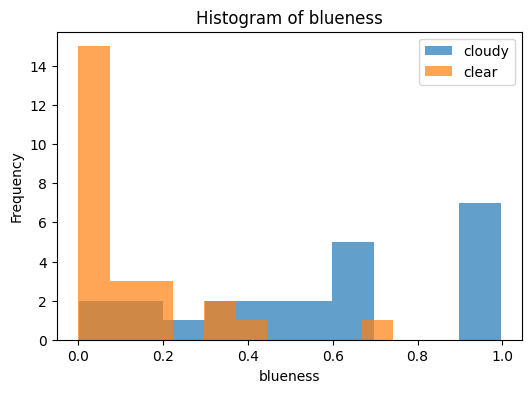

blueness threshold set to 0.346


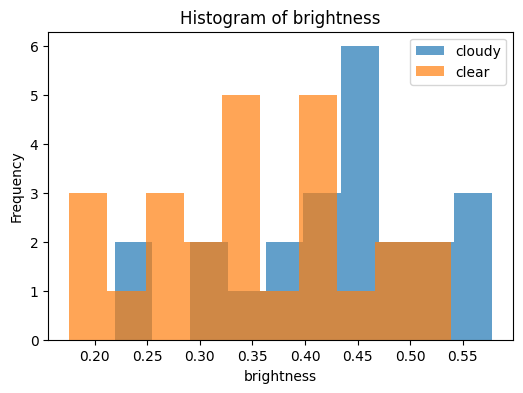

brightness threshold set to 0.389


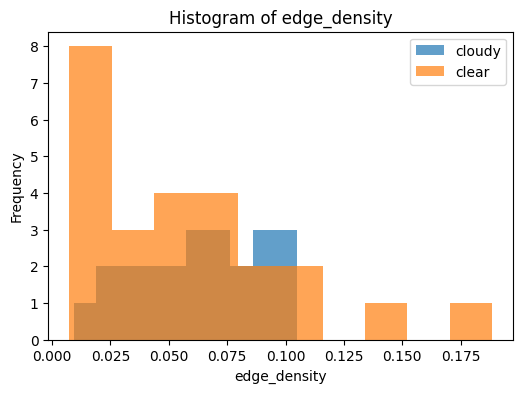

edge_density threshold set to 0.060


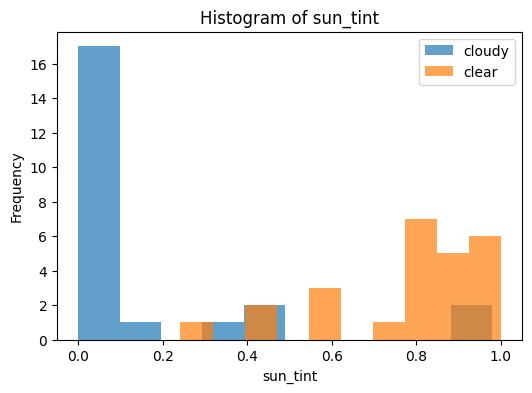

sun_tint threshold set to 0.468


In [ ]:
train_features = { 'blueness': [], 'brightness': [], 'edge_density': [], 'sun_tint': [], 'label': [] }

for img_path, label in zip(train_images, train_labels):
    b, br, e, s = extract_features(img_path)
    train_features['blueness'].append(b)
    train_features['brightness'].append(br)
    train_features['edge_density'].append(e)
    train_features['sun_tint'].append(s)
    train_features['label'].append(label)

features_to_plot = ['blueness','brightness','edge_density','sun_tint']
thresholds = {}

for feat in features_to_plot:
    cloudy_vals = [v for v,l in zip(train_features[feat], train_features['label']) if l=='cloudy']
    clear_vals = [v for v,l in zip(train_features[feat], train_features['label']) if l=='clear']
    plt.figure(figsize=(6,4))
    plt.hist(cloudy_vals, bins=10, alpha=0.7, label='cloudy')
    plt.hist(clear_vals, bins=10, alpha=0.7, label='clear')
    plt.title(f'Histogram of {feat}')
    plt.xlabel(feat)
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()
    thresholds[feat] = (np.mean(cloudy_vals)+np.mean(clear_vals))/2
    print(f'{feat} threshold set to {thresholds[feat]:.3f}')

## Individual Feature Classifiers

Now test each feature separately — one simple rule per feature.

In [ ]:
def classify_single(b, br, e, s, thresholds, feature_name):
    if feature_name == 'blueness':
        return 'cloudy' if b > thresholds['blueness'] else 'clear'
    elif feature_name == 'brightness':
        return 'cloudy' if br < thresholds['brightness'] else 'clear'
    elif feature_name == 'edge_density':
        return 'cloudy' if e > thresholds['edge_density'] else 'clear'
    elif feature_name == 'sun_tint':
        return 'cloudy' if s < thresholds['sun_tint'] else 'clear'

results = {}
for feat in features_to_plot:
    y_true, y_pred = [], []
    for img_path, label in zip(test_images, test_labels):
        b, br, e, s = extract_features(img_path)
        pred = classify_single(b, br, e, s, thresholds, feat)
        y_true.append(label)
        y_pred.append(pred)
    cm = confusion_matrix(y_true, y_pred, labels=['cloudy','clear'])
    precision = precision_score(y_true, y_pred, pos_label='cloudy')
    recall = recall_score(y_true, y_pred, pos_label='cloudy')
    results[feat] = (cm, precision, recall)

for feat, (cm, p, r) in results.items():
    print(f'\n=== {feat.upper()} ===')
    print('Confusion Matrix:\n', cm)
    print(f'Precision: {p:.3f}, Recall: {r:.3f}')


=== BLUENESS ===
Confusion Matrix:
 [[11  6]
 [ 4 11]]
Precision: 0.733, Recall: 0.647

=== BRIGHTNESS ===
Confusion Matrix:
 [[8 9]
 [8 7]]
Precision: 0.500, Recall: 0.471

=== EDGE_DENSITY ===
Confusion Matrix:
 [[ 5 12]
 [ 7  8]]
Precision: 0.417, Recall: 0.294

=== SUN_TINT ===
Confusion Matrix:
 [[13  4]
 [ 3 12]]
Precision: 0.812, Recall: 0.765


## Combined Classifier (Voting Rule)

We combine all four features: a majority vote determines the class. Each feature votes for 'cloudy' if it meets the rule.

In [ ]:
def classify_combined(b, br, e, s, thresholds):
    votes = 0
    votes += b > thresholds['blueness']      # cloudy -> more blue
    votes += br < thresholds['brightness']   # cloudy -> less bright
    votes += e > thresholds['edge_density']  # cloudy -> more edges
    votes += s < thresholds['sun_tint']      # cloudy -> less orange
    return 'cloudy' if votes >= 2 else 'clear'

y_true, y_pred = [], []
for img_path, label in zip(test_images, test_labels):
    b, br, e, s = extract_features(img_path)
    pred = classify_combined(b, br, e, s, thresholds)
    y_true.append(label)
    y_pred.append(pred)

cm = confusion_matrix(y_true, y_pred, labels=['cloudy','clear'])
precision = precision_score(y_true, y_pred, pos_label='cloudy')
recall = recall_score(y_true, y_pred, pos_label='cloudy')

print('Combined Classifier Results:')
print(cm)
print(f'Precision: {precision:.3f}, Recall: {recall:.3f}')

Combined Classifier Results:
[[12  5]
 [ 6  9]]
Precision: 0.667, Recall: 0.706


## Misclassified Samples Visualization

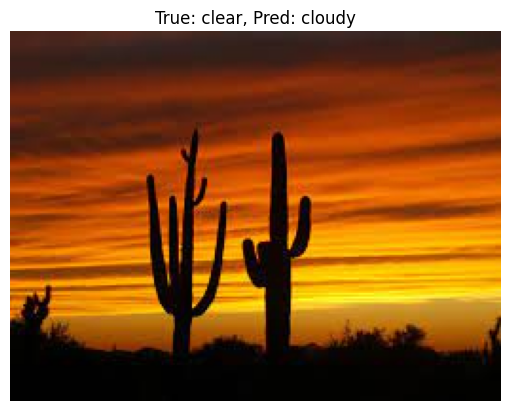

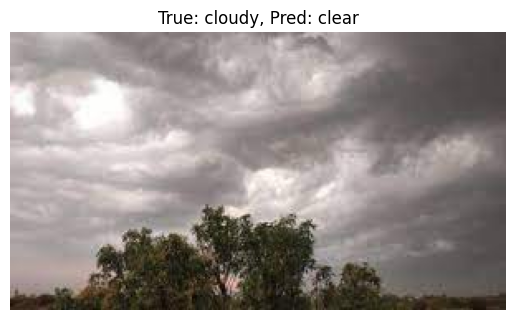

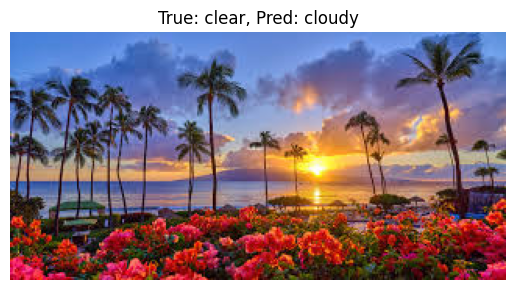

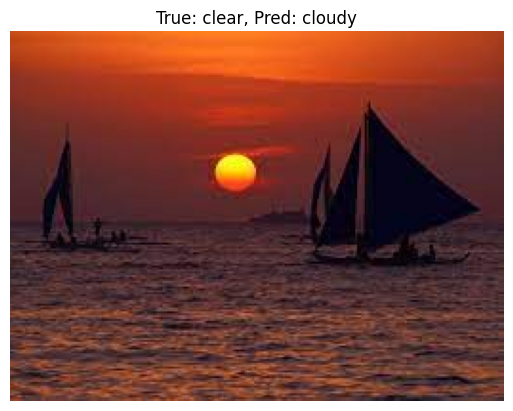

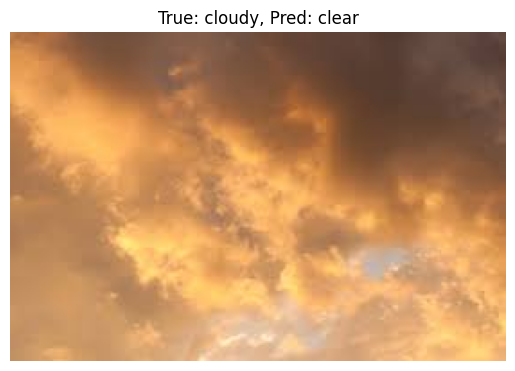

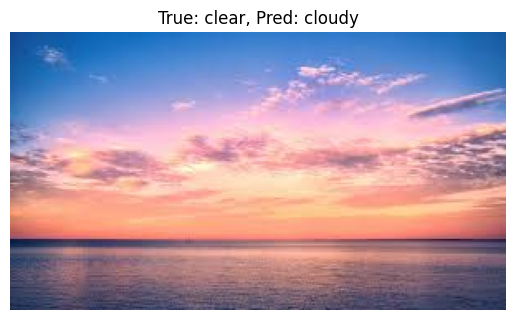

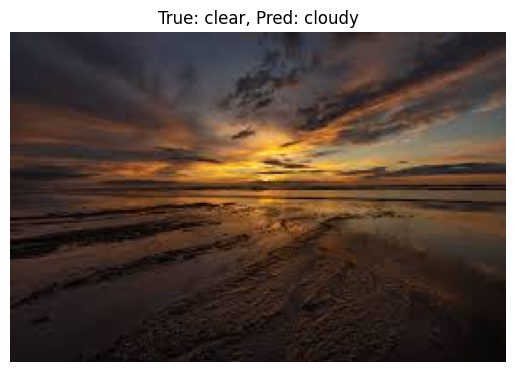

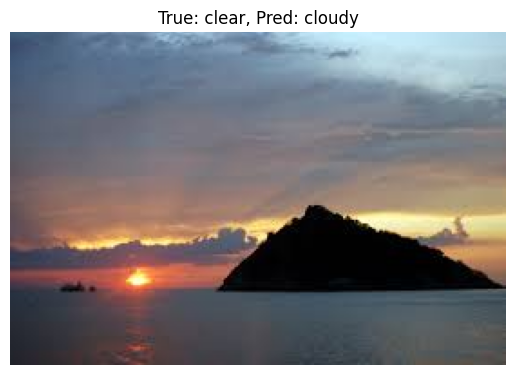

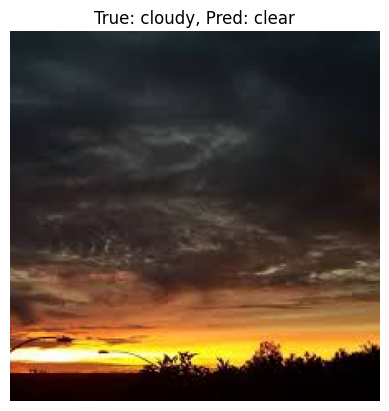

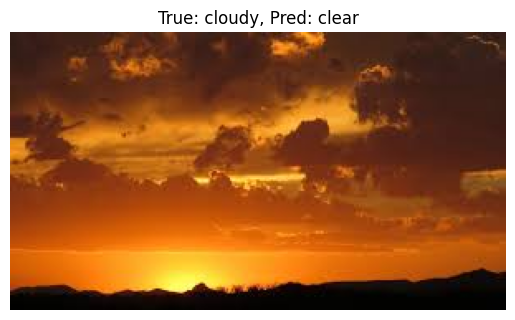

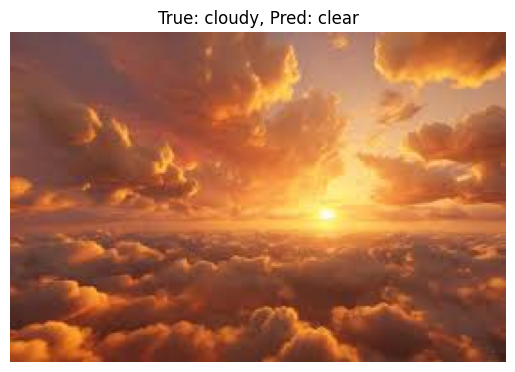

In [ ]:
for img_path, label, pred in zip(test_images, test_labels, y_pred):
    if label != pred:
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
        plt.title(f'True: {label}, Pred: {pred}')
        plt.axis('off')
        plt.show()

## Conclusion

Among the evaluated criteria, **edge density** proved the least reliable. Both bright sunny skies (with sunlight or reflections) and cloudy skies (with many cloud textures) produce many edges, causing confusion.

**Color-based criteria** (blueness, sun tint) can also mislead the classifier — for instance, a cloudy image illuminated by sunlight can appear orange, while a clear sky near sunset may appear reddish and be labeled cloudy.

Overall, a **combination of features** (blueness, brightness, edge density, and tint) yields the most balanced results, but the highest accuracy is achieved with **orangish sun tint**. While the accuracy is not perfect, the classifier remains *interpretable* and consistent with human reasoning about the visual cues that separate cloudy and clear skies.